<a href="https://colab.research.google.com/github/Soumita-Karmakar/Portfolio/blob/main/student_performance_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [243]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

In [244]:
!pip install xlrd openpyxl

In [245]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [246]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [247]:
df = pd.read_csv('/content/drive/MyDrive/Student Performance Prediction and Academic Risk Analysis /dataset/student_performance_challenge33.csv.xls', sep='\t')
print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,Student_ID,Attendance_Percentage,Internal_Marks,Assignment_Score,Previous_Semester_Score,Study_Hours_Per_Day,Engagement_Level,Final_Academic_Score,Performance_Band,Performance_Change
0,STU00001,83.96,61.64,62.50,67.99,4.02,Medium,74.95,Good,6.96
1,STU00002,76.34,61.20,67.72,69.54,3.92,High,70.40,Good,0.86
2,STU00003,85.77,41.07,63.64,70.90,2.10,Low,57.58,Average,-13.32
3,STU00004,96.28,63.05,73.55,83.26,4.37,High,91.02,Excellent,7.76
4,STU00005,75.19,78.99,88.76,59.54,1.26,Medium,82.63,Good,23.09


In [248]:
# Display dataset information
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (5010, 10)

Column Names:
['Student_ID', 'Attendance_Percentage', 'Internal_Marks', 'Assignment_Score', 'Previous_Semester_Score', 'Study_Hours_Per_Day', 'Engagement_Level', 'Final_Academic_Score', 'Performance_Band', 'Performance_Change']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5010 entries, 0 to 5009
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Student_ID               5010 non-null   object 
 1   Attendance_Percentage    5002 non-null   float64
 2   Internal_Marks           5010 non-null   float64
 3   Assignment_Score         5003 non-null   float64
 4   Previous_Semester_Score  5010 non-null   float64
 5   Study_Hours_Per_Day      5005 non-null   float64
 6   Engagement_Level         5005 non-null   object 
 7   Final_Academic_Score     5010 non-null   float64
 8   Performance_Band         5010 non-null   object 
 9   Performance_Chang

**Step 2 — Data preprocessing**

In [249]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Calculate total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
Student_ID                 0
Attendance_Percentage      8
Internal_Marks             0
Assignment_Score           7
Previous_Semester_Score    0
Study_Hours_Per_Day        5
Engagement_Level           5
Final_Academic_Score       0
Performance_Band           0
Performance_Change         0
dtype: int64

Total Missing Values: 25


In [250]:
# Handle missing values
df.fillna(0, inplace=True)

print("Missing values handled successfully!")

Missing values handled successfully!


In [251]:
#Check missing values again
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
Student_ID                 0
Attendance_Percentage      0
Internal_Marks             0
Assignment_Score           0
Previous_Semester_Score    0
Study_Hours_Per_Day        0
Engagement_Level           0
Final_Academic_Score       0
Performance_Band           0
Performance_Change         0
dtype: int64

Total Missing Values: 0


In [252]:
# Count duplicate records
print("Duplicate Records:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Duplicate Records: 7
Dataset Shape After Removing Duplicates: (5003, 10)


In [253]:
#Remove duplicate records
df.drop_duplicates(inplace=True)

print("Duplicate records removed successfully!")
print("Dataset Shape:", df.shape)

Duplicate records removed successfully!
Dataset Shape: (5003, 10)


In [254]:
#Verify duplicates
print("Remaining Duplicates:", df.duplicated().sum())

Remaining Duplicates: 0


In [255]:
# Display data types of all columns
print(df.dtypes)

Student_ID                  object
Attendance_Percentage      float64
Internal_Marks             float64
Assignment_Score           float64
Previous_Semester_Score    float64
Study_Hours_Per_Day        float64
Engagement_Level            object
Final_Academic_Score       float64
Performance_Band            object
Performance_Change         float64
dtype: object


In [256]:
# Identify numerical columns
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

# Identify categorical columns
categorical_columns = df.select_dtypes(include=["object"]).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())

Numerical Columns:
['Attendance_Percentage', 'Internal_Marks', 'Assignment_Score', 'Previous_Semester_Score', 'Study_Hours_Per_Day', 'Final_Academic_Score', 'Performance_Change']

Categorical Columns:
['Student_ID', 'Engagement_Level', 'Performance_Band']


In [257]:
# Convert categorical values into numerical values

df["Engagement_Level"] = df["Engagement_Level"].map({
    "Low": 0,
    "Medium": 1,
    "High": 2
})

print("Categorical data converted successfully!")

Categorical data converted successfully!


In [258]:
#Check converted values
print(df["Engagement_Level"].value_counts())

Engagement_Level
1.0    2535
2.0    1452
0.0    1011
Name: count, dtype: int64


In [259]:
#Check unique values
print(df["Engagement_Level"].unique())

[ 1.  2.  0. nan]


In [260]:
#fix missing values
df["Engagement_Level"] = df["Engagement_Level"].fillna(
    df["Engagement_Level"].mode()[0]
)

In [261]:
#Check missing values
print(df["Engagement_Level"].value_counts())
print("Missing Values:", df["Engagement_Level"].isnull().sum())

Engagement_Level
1.0    2540
2.0    1452
0.0    1011
Name: count, dtype: int64
Missing Values: 0


In [262]:
#Check missing values in the entire dataset
print(df.isnull().sum())
print("\nTotal Missing Values:", df.isnull().sum().sum())

Student_ID                 0
Attendance_Percentage      0
Internal_Marks             0
Assignment_Score           0
Previous_Semester_Score    0
Study_Hours_Per_Day        0
Engagement_Level           0
Final_Academic_Score       0
Performance_Band           0
Performance_Change         0
dtype: int64

Total Missing Values: 0


In [263]:
print(df.head())
print(df.dtypes)

  Student_ID  Attendance_Percentage  Internal_Marks  Assignment_Score  \
0   STU00001                  83.96           61.64             62.50   
1   STU00002                  76.34           61.20             67.72   
2   STU00003                  85.77           41.07             63.64   
3   STU00004                  96.28           63.05             73.55   
4   STU00005                  75.19           78.99             88.76   

   Previous_Semester_Score  Study_Hours_Per_Day  Engagement_Level  \
0                    67.99                 4.02               1.0   
1                    69.54                 3.92               2.0   
2                    70.90                 2.10               0.0   
3                    83.26                 4.37               2.0   
4                    59.54                 1.26               1.0   

   Final_Academic_Score Performance_Band  Performance_Change  
0                 74.95             Good                6.96  
1                 70

In [264]:
# Identify outliers using IQR method

continuous_columns = [
    "Attendance_Percentage",
    "Internal_Marks",
    "Assignment_Score",
    "Previous_Semester_Score",
    "Study_Hours_Per_Day",
    "Final_Academic_Score"
]

for col in continuous_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers), "outliers")

Attendance_Percentage : 32 outliers
Internal_Marks : 18 outliers
Assignment_Score : 35 outliers
Previous_Semester_Score : 21 outliers
Study_Hours_Per_Day : 9 outliers
Final_Academic_Score : 33 outliers


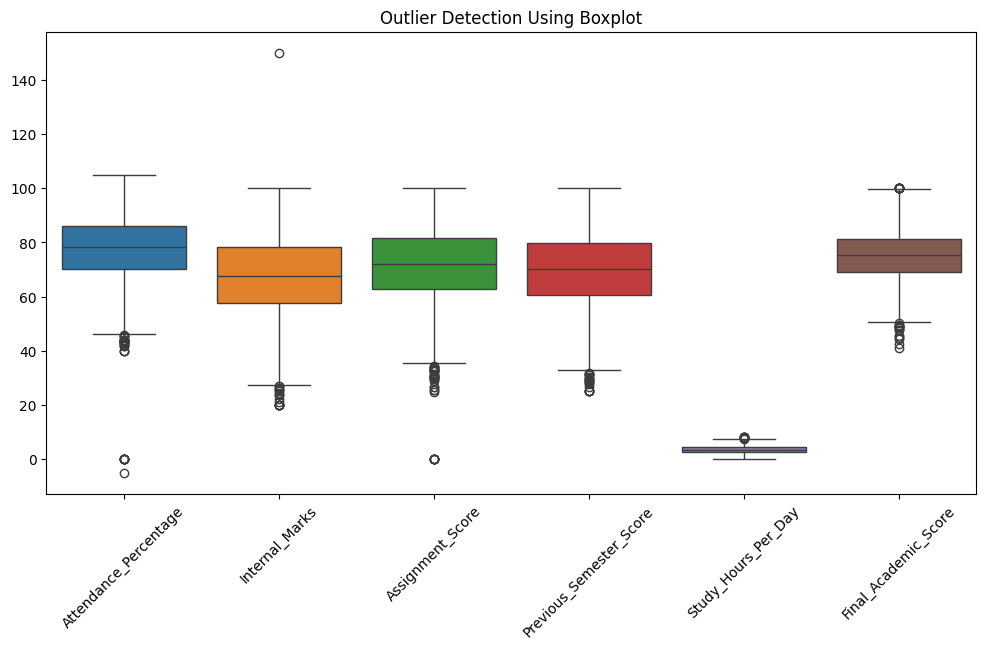

In [265]:
#Visualize outliers using boxplots
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[continuous_columns])
plt.xticks(rotation=45)
plt.title("Outlier Detection Using Boxplot")
plt.show()

In [266]:
# Handle outliers using IQR capping

for col in continuous_columns[:-1]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

print("Outliers handled successfully!")

Outliers handled successfully!


In [267]:
# Check outliers after handling

for col in continuous_columns[:-1]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers), "outliers")

Attendance_Percentage : 0 outliers
Internal_Marks : 0 outliers
Assignment_Score : 0 outliers
Previous_Semester_Score : 0 outliers
Study_Hours_Per_Day : 0 outliers


**Step 3 — Exploratory Data Analysis (EDA) and Visualization**

In [268]:
# Display statistical summary of numerical data
print("Statistical Summary:")
print(df.describe())

Statistical Summary:
       Attendance_Percentage  Internal_Marks  Assignment_Score  \
count            5003.000000     5003.000000       5003.000000   
mean               77.894166       67.781083         71.985321   
std                11.636732       14.863781         13.682806   
min                46.175000       27.010000         34.647500   
25%                70.070000       57.700000         62.720000   
50%                78.160000       67.730000         72.110000   
75%                86.000000       78.160000         81.435000   
max               105.000000      108.850000        100.000000   

       Previous_Semester_Score  Study_Hours_Per_Day  Engagement_Level  \
count              5003.000000          5003.000000       5003.000000   
mean                 70.158635             3.480181          1.088147   
std                  13.778216             1.449046          0.696155   
min                  31.910000             0.000000          0.000000   
25%                

In [269]:
# Calculate average marks
print("Average Internal Marks:", df["Internal_Marks"].mean())
print("Average Assignment Score:", df["Assignment_Score"].mean())
print("Average Previous Semester Score:", df["Previous_Semester_Score"].mean())
print("Average Final Academic Score:", df["Final_Academic_Score"].mean())

# Find highest and lowest final scores
print("\nHighest Final Score:", df["Final_Academic_Score"].max())
print("Lowest Final Score:", df["Final_Academic_Score"].min())

Average Internal Marks: 67.78108334999001
Average Assignment Score: 71.98532130721567
Average Previous Semester Score: 70.15863481910854
Average Final Academic Score: 75.1517269638217

Highest Final Score: 100.0
Lowest Final Score: 41.05


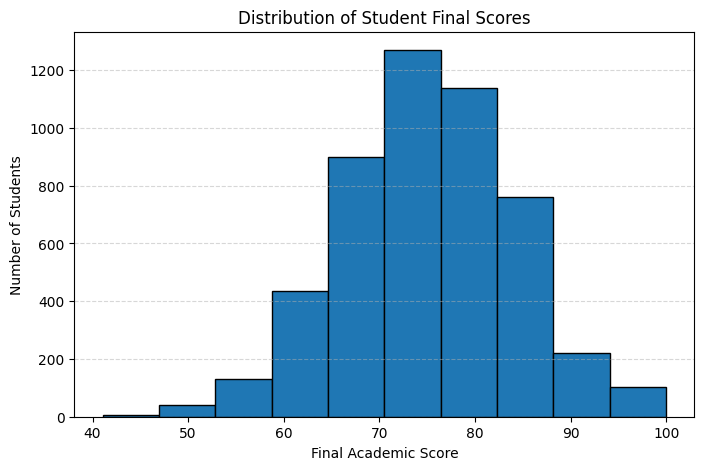

In [270]:
# Distribution of final academic scores

plt.figure(figsize=(8, 5))

plt.hist(
    df["Final_Academic_Score"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Student Final Scores")
plt.xlabel("Final Academic Score")
plt.ylabel("Number of Students")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

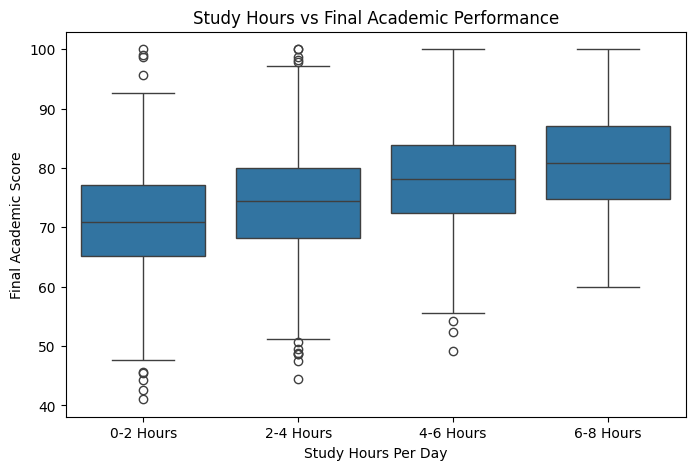

In [271]:
# Group study hours into ranges

df["Study_Hours_Group"] = pd.cut(
    df["Study_Hours_Per_Day"],
    bins=[-0.01, 2, 4, 6, 8.1],
    labels=["0-2 Hours", "2-4 Hours", "4-6 Hours", "6-8 Hours"]
)

# Study hours vs final academic score

plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Study_Hours_Group",
    y="Final_Academic_Score",
    data=df
)

plt.title("Study Hours vs Final Academic Performance")
plt.xlabel("Study Hours Per Day")
plt.ylabel("Final Academic Score")

plt.show()

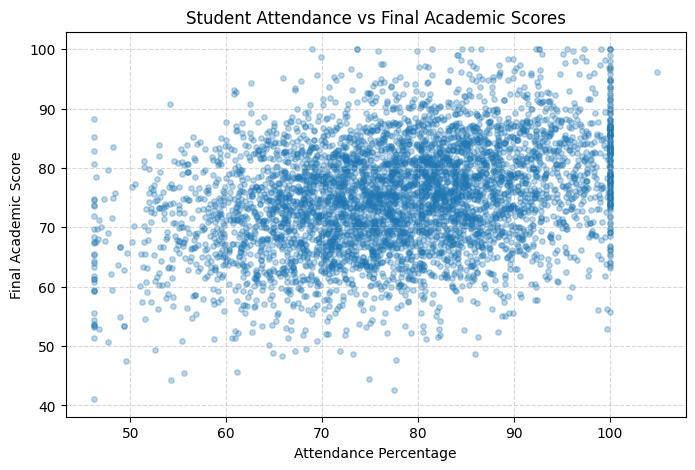

In [272]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Attendance_Percentage"],
    df["Final_Academic_Score"],
    alpha=0.3,
    s=15
)

plt.title("Student Attendance vs Final Academic Scores")
plt.xlabel("Attendance Percentage")
plt.ylabel("Final Academic Score")

plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [273]:
# Calculate correlation between numerical variables

correlation = df.select_dtypes(include=["int64", "float64"]).corr()

# Display correlation with final academic score

print("Correlation with Final Academic Score:")
print(correlation["Final_Academic_Score"].sort_values(ascending=False))

Correlation with Final Academic Score:
Final_Academic_Score       1.000000
Internal_Marks             0.496513
Performance_Change         0.345905
Study_Hours_Per_Day        0.325188
Attendance_Percentage      0.318891
Previous_Semester_Score    0.299469
Engagement_Level           0.269732
Assignment_Score           0.224047
Name: Final_Academic_Score, dtype: float64


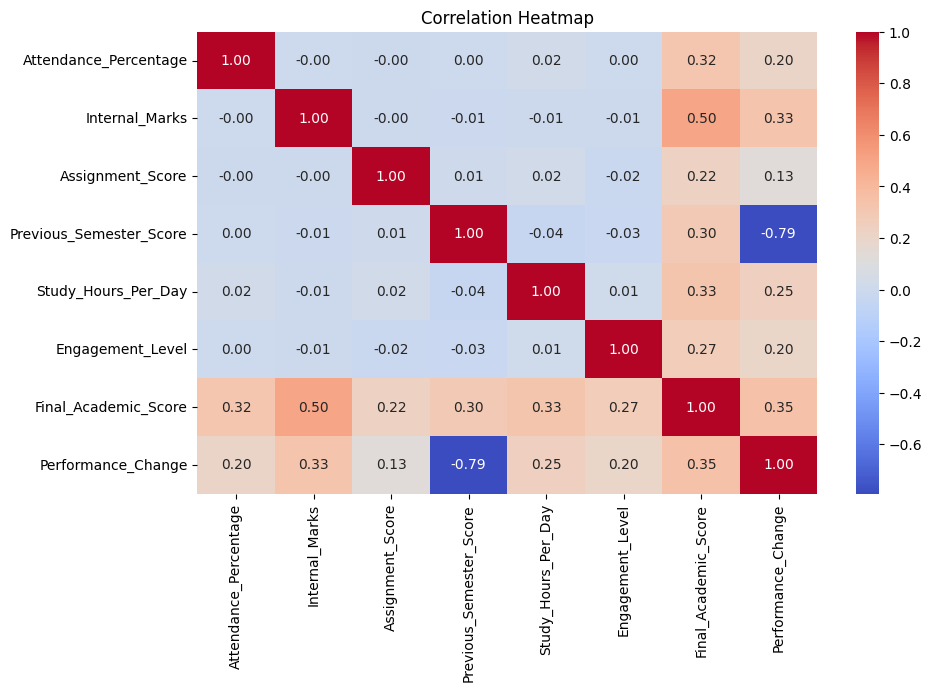

In [274]:
# Correlation Heatmap

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

**Step 4 — Machine Learning Model Development**

In [275]:
# Import machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans

# Import preprocessing library
from sklearn.preprocessing import StandardScaler

# Import evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Machine Learning Libraries Imported Successfully!")

Machine Learning Libraries Imported Successfully!


In [276]:
print(df["Engagement_Level"].value_counts(dropna=False))
print("Missing Values:", df["Engagement_Level"].isnull().sum())

Engagement_Level
1.0    2540
2.0    1452
0.0    1011
Name: count, dtype: int64
Missing Values: 0


In [277]:
# Select input features
X = df[[
    "Attendance_Percentage",
    "Internal_Marks",
    "Assignment_Score",
    "Previous_Semester_Score",
    "Study_Hours_Per_Day",
    "Engagement_Level"
]]

# Select target variable
y = df["Final_Academic_Score"]

In [278]:
# Split dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# Check missing values
print("Missing values:", X_train.isnull().sum().sum())

Training Data: (4002, 6)
Testing Data: (1001, 6)
Missing values: 0


**Model 1 — Linear Regression**


In [279]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, linear_predictions)
mse = mean_squared_error(y_test, linear_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, linear_predictions)

print("========== LINEAR REGRESSION ==========")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 2))

========== LINEAR REGRESSION ==========
Mean Absolute Error: 4.03
Mean Squared Error: 25.47
Root Mean Squared Error: 5.05
R2 Score: 0.68


In [280]:
# Compare actual and predicted scores

comparison = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": linear_predictions
})

print(comparison.head(10).round(2))

   Actual Score  Predicted Score
0         76.01            67.64
1         65.47            69.61
2         44.54            62.14
3         75.69            75.65
4         81.55            77.67
5         76.61            80.06
6         69.79            71.34
7         88.35            79.74
8         77.58            74.11
9         76.67            72.99


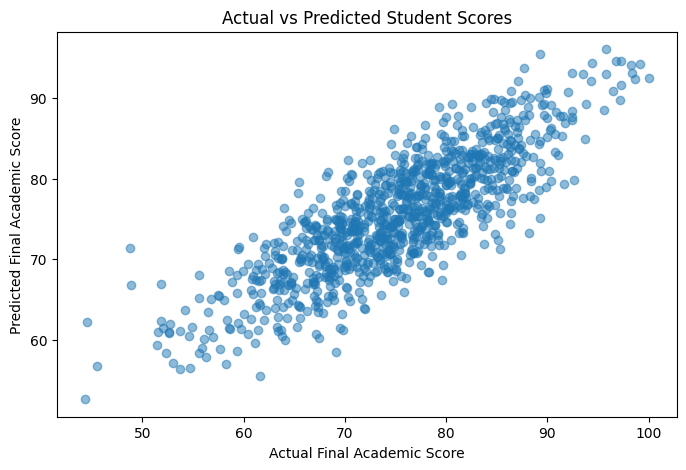

In [281]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, linear_predictions, alpha=0.5)

plt.xlabel("Actual Final Academic Score")
plt.ylabel("Predicted Final Academic Score")
plt.title("Actual vs Predicted Student Scores")

plt.show()

**Model 2 — Logistic Regression**

In [282]:
# Select categorical target
y_logistic = df["Performance_Band"]

# Split target using the same random state
_, _, y_train_lr, y_test_lr = train_test_split(
    X, y_logistic,
    test_size=0.20,
    random_state=42,
    stratify=y_logistic
)

# Scale features
scaler_lr = StandardScaler()
X_train_scaled = scaler_lr.fit_transform(X_train)
X_test_scaled = scaler_lr.transform(X_test)

# Create and train Logistic Regression
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_scaled, y_train_lr)

# Predict
logistic_predictions = logistic_model.predict(X_test_scaled)

# Evaluate
print("========== LOGISTIC REGRESSION ==========")
print("Accuracy:", round(
    accuracy_score(y_test_lr, logistic_predictions) * 100, 2
), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_lr, logistic_predictions))

print("\nClassification Report:")
print(classification_report(y_test_lr, logistic_predictions))

========== LOGISTIC REGRESSION ==========
Accuracy: 58.14 %

Confusion Matrix:
[[  0   0   0  15]
 [  0   0   0 270]
 [  0   0   0 134]
 [  0   0   0 582]]

Classification Report:
              precision    recall  f1-score   support

     At Risk       0.00      0.00      0.00        15
     Average       0.00      0.00      0.00       270
   Excellent       0.00      0.00      0.00       134
        Good       0.58      1.00      0.74       582

    accuracy                           0.58      1001
   macro avg       0.15      0.25      0.18      1001
weighted avg       0.34      0.58      0.43      1001



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [283]:
logistic_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced"
)

logistic_model.fit(X_train_scaled, y_train_lr)

LogisticRegression(class_weight='balanced', max_iter=2000)

In [284]:
logistic_predictions = logistic_model.predict(X_test_scaled)

print("Accuracy:", round(
    accuracy_score(y_test_lr, logistic_predictions) * 100, 2
), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_lr, logistic_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test_lr,
    logistic_predictions,
    zero_division=0
))

Accuracy: 25.37 %

Confusion Matrix:
[[  6   4   2   3]
 [103  77  11  79]
 [ 43  45   2  44]
 [233 163  17 169]]

Classification Report:
              precision    recall  f1-score   support

     At Risk       0.02      0.40      0.03        15
     Average       0.27      0.29      0.28       270
   Excellent       0.06      0.01      0.02       134
        Good       0.57      0.29      0.39       582

    accuracy                           0.25      1001
   macro avg       0.23      0.25      0.18      1001
weighted avg       0.41      0.25      0.30      1001



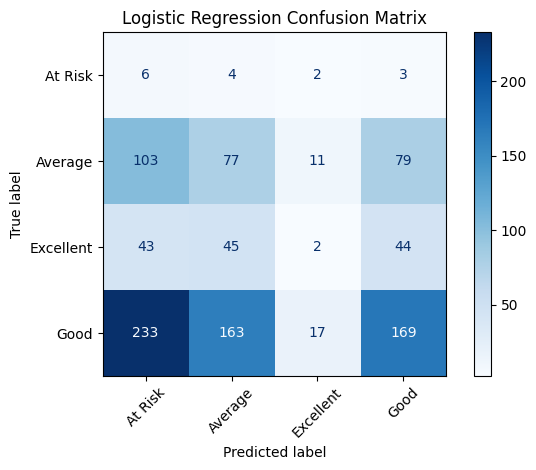

In [285]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_lr,
    logistic_predictions,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

**Model 3 — K-Nearest Neighbors (KNN)**

In [286]:
# Create KNN model
knn_model = KNeighborsClassifier(n_neighbors=11)

# Train the model
knn_model.fit(X_train_scaled, y_train_lr)

# Predict performance categories
knn_predictions = knn_model.predict(X_test_scaled)

# Evaluate the model
print("========== K-NEAREST NEIGHBORS ==========")

print("Accuracy:", round(
    accuracy_score(y_test_lr, knn_predictions) * 100, 2
), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_lr, knn_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test_lr,
    knn_predictions,
    zero_division=0
))

========== K-NEAREST NEIGHBORS ==========
Accuracy: 52.95 %

Confusion Matrix:
[[  0   0   0  15]
 [  0  43   4 223]
 [  0  21   0 113]
 [  0  83  12 487]]

Classification Report:
              precision    recall  f1-score   support

     At Risk       0.00      0.00      0.00        15
     Average       0.29      0.16      0.21       270
   Excellent       0.00      0.00      0.00       134
        Good       0.58      0.84      0.69       582

    accuracy                           0.53      1001
   macro avg       0.22      0.25      0.22      1001
weighted avg       0.42      0.53      0.45      1001



**Model 4 — K-Means Clustering**

In [287]:
# Select features for clustering
cluster_data = df[[
    "Attendance_Percentage",
    "Internal_Marks",
    "Assignment_Score",
    "Previous_Semester_Score",
    "Study_Hours_Per_Day",
    "Engagement_Level"
]]

# Scale the data
scaler_kmeans = StandardScaler()
cluster_scaled = scaler_kmeans.fit_transform(cluster_data)

# Create K-Means model
kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Perform clustering
df["Cluster"] = kmeans_model.fit_predict(cluster_scaled)

# Calculate average final score for each cluster
cluster_summary = df.groupby("Cluster").agg(
    Average_Final_Score=("Final_Academic_Score", "mean"),
    Student_Count=("Final_Academic_Score", "count")
)

# Identify cluster performance order
sorted_clusters = cluster_summary["Average_Final_Score"].sort_values().index

# Assign performance labels
cluster_labels = {
    sorted_clusters[0]: "Cluster 1 - Lower Performance",
    sorted_clusters[1]: "Cluster 2 - Medium Performance",
    sorted_clusters[2]: "Cluster 3 - Higher Performance"
}

# Add performance groups
df["Performance_Group"] = df["Cluster"].map(cluster_labels)

# Display results
print("========== K-MEANS CLUSTERING ==========")

print(df[[
    "Final_Academic_Score",
    "Cluster",
    "Performance_Group"
]].head(10))

print("\nCluster Summary:")
print(df.groupby("Performance_Group").agg(
    Student_Count=("Final_Academic_Score", "count"),
    Average_Final_Score=("Final_Academic_Score", "mean")
))

========== K-MEANS CLUSTERING ==========
   Final_Academic_Score  Cluster               Performance_Group
0                 74.95        0  Cluster 2 - Medium Performance
1                 70.40        2  Cluster 3 - Higher Performance
2                 57.58        1   Cluster 1 - Lower Performance
3                 91.02        2  Cluster 3 - Higher Performance
4                 82.63        1   Cluster 1 - Lower Performance
5                 54.31        1   Cluster 1 - Lower Performance
6                 84.04        2  Cluster 3 - Higher Performance
7                 82.74        2  Cluster 3 - Higher Performance
8                 61.24        1   Cluster 1 - Lower Performance
9                 96.22        2  Cluster 3 - Higher Performance

Cluster Summary:
                                Student_Count  Average_Final_Score
Performance_Group                                                 
Cluster 1 - Lower Performance            1835            72.947041
Cluster 2 - Medium Perfor

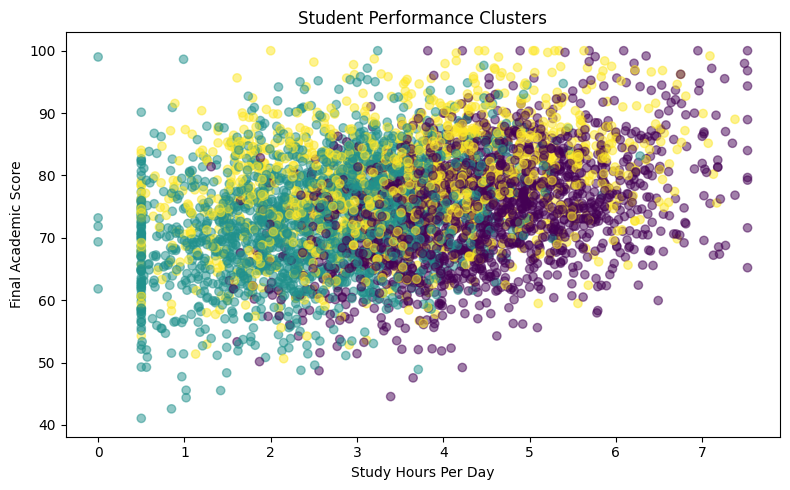

In [288]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Study_Hours_Per_Day"],
    df["Final_Academic_Score"],
    c=df["Cluster"],
    cmap="viridis",
    alpha=0.5
)

plt.xlabel("Study Hours Per Day")
plt.ylabel("Final Academic Score")
plt.title("Student Performance Clusters")

plt.tight_layout()
plt.show()

**Step 5 — Model Optimization and Cross-Validation**

In [289]:
# Import optimization and cross-validation libraries
from sklearn.model_selection import cross_val_score

In [290]:
# Perform 5-fold cross-validation
linear_cv_scores = cross_val_score(
    linear_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("========== LINEAR REGRESSION OPTIMIZATION ==========")
print("Cross Validation Scores:", linear_cv_scores)
print("Average R2 Score:", round(linear_cv_scores.mean(), 3))

========== LINEAR REGRESSION OPTIMIZATION ==========
Cross Validation Scores: [0.68873717 0.67236427 0.69083974 0.66058686 0.66758731]
Average R2 Score: 0.676


In [291]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

logistic_parameters = {
    "C": [0.01, 0.1, 1, 10, 100],
    "class_weight": [None, "balanced"]
}

logistic_grid = GridSearchCV(
    LogisticRegression(max_iter=2000),
    logistic_parameters,
    cv=5,
    scoring="f1_macro"
)

logistic_grid.fit(X_train_scaled, y_train_lr)

best_logistic_model = logistic_grid.best_estimator_

print("========== LOGISTIC REGRESSION ==========")
print("Best Parameters:", logistic_grid.best_params_)
print("Best Cross Validation F1 Score:",
      round(logistic_grid.best_score_, 3))

========== LOGISTIC REGRESSION ==========
Best Parameters: {'C': 0.01, 'class_weight': None}
Best Cross Validation F1 Score: 0.184


In [292]:
from sklearn.metrics import classification_report, accuracy_score

logistic_predictions = best_logistic_model.predict(X_test_scaled)

print("========== OPTIMIZED LOGISTIC REGRESSION ==========")
print("Accuracy:", round(accuracy_score(y_test_lr, logistic_predictions) * 100, 2), "%")

print(classification_report(
    y_test_lr,
    logistic_predictions,
    zero_division=0
))

========== OPTIMIZED LOGISTIC REGRESSION ==========
Accuracy: 58.14 %
              precision    recall  f1-score   support

     At Risk       0.00      0.00      0.00        15
     Average       0.00      0.00      0.00       270
   Excellent       0.00      0.00      0.00       134
        Good       0.58      1.00      0.74       582

    accuracy                           0.58      1001
   macro avg       0.15      0.25      0.18      1001
weighted avg       0.34      0.58      0.43      1001



In [293]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 6):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(cluster_scaled)

    score = silhouette_score(cluster_scaled, labels)

    silhouette_scores.append(score)

    print("Clusters:", k, "Silhouette Score:", round(score, 3))

best_k = range(2, 6)[np.argmax(silhouette_scores)]

print("\nBest Number of Clusters:", best_k)

Clusters: 2 Silhouette Score: 0.113
Clusters: 3 Silhouette Score: 0.119
Clusters: 4 Silhouette Score: 0.113
Clusters: 5 Silhouette Score: 0.113

Best Number of Clusters: 3


In [294]:
# Predict using optimized models
best_logistic_predictions = best_logistic_model.predict(X_test_scaled)

best_knn_predictions = knn_model.predict(X_test_scaled)

# Calculate accuracy
logistic_accuracy = accuracy_score(
    y_test_lr,
    best_logistic_predictions
) * 100

knn_accuracy = accuracy_score(
    y_test_lr,
    best_knn_predictions
) * 100

# Display comparison
print("========== OPTIMIZED MODEL COMPARISON ==========")

print("Optimized Logistic Regression Accuracy:",
      round(logistic_accuracy, 2), "%")

print("Optimized KNN Accuracy:",
      round(knn_accuracy, 2), "%")

========== OPTIMIZED MODEL COMPARISON ==========
Optimized Logistic Regression Accuracy: 58.14 %
Optimized KNN Accuracy: 52.95 %


**Step 6 — Final Results and Student Prediction System**

In [295]:
# Compare all models

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Logistic Regression",
        "KNN",
        "K-Means"
    ],
    "Evaluation Metric": [
        "R2 Score",
        "Accuracy",
        "Accuracy",
        "Silhouette Score"
    ],
    "Performance": [
        round(linear_r2, 3),
        round(logistic_accuracy, 2),
        round(knn_accuracy, 2),
        round(max(silhouette_scores), 3)
    ]
})

print("========== FINAL MODEL COMPARISON ==========")
print(model_comparison)

========== FINAL MODEL COMPARISON ==========
                 Model Evaluation Metric  Performance
0    Linear Regression          R2 Score        0.672
1  Logistic Regression          Accuracy       58.140
2                  KNN          Accuracy       52.950
3              K-Means  Silhouette Score        0.119


In [296]:
# Compare actual and predicted marks
prediction_results = pd.DataFrame({
    "Actual Marks": y_test,
    "Predicted Marks": linear_predictions
})

prediction_results["Predicted Marks"] = (
    prediction_results["Predicted Marks"].round(2)
)

print("========== FINAL MARKS PREDICTION ==========")
print(prediction_results.head(10))

========== FINAL MARKS PREDICTION ==========
      Actual Marks  Predicted Marks
414          76.01            67.64
1815         65.47            69.61
642          44.54            62.14
1056         75.69            75.65
4507         81.55            77.67
106          76.61            80.06
1726         69.79            71.34
742          88.35            79.74
1018         77.58            74.11
1672         76.67            72.99


In [297]:
# Predict performance probabilities
performance_probabilities = best_logistic_model.predict_proba(
    X_test_scaled
)

# Get predicted performance categories
performance_predictions = best_logistic_model.predict(
    X_test_scaled
)

# Display prediction results
performance_results = pd.DataFrame({
    "Actual Performance": y_test_lr.values,
    "Predicted Performance": performance_predictions,
    "Prediction Confidence (%)": (
        performance_probabilities.max(axis=1) * 100
    ).round(2)
})

print("========== STUDENT PERFORMANCE PREDICTION ==========")
print(performance_results.head(10))

========== STUDENT PERFORMANCE PREDICTION ==========
  Actual Performance Predicted Performance  Prediction Confidence (%)
0               Good                  Good                      59.58
1            At Risk                  Good                      59.13
2          Excellent                  Good                      58.34
3               Good                  Good                      56.66
4               Good                  Good                      58.34
5               Good                  Good                      58.36
6               Good                  Good                      58.01
7               Good                  Good                      56.23
8               Good                  Good                      54.01
9            Average                  Good                      57.23


In [298]:
# Create academic risk categories
def identify_risk(marks):

    if marks < 40:
        return "High Risk"

    elif marks < 60:
        return "Medium Risk"

    else:
        return "Low Risk"


# Assign risk levels
prediction_results["Academic Risk"] = (
    prediction_results["Predicted Marks"].apply(identify_risk)
)

print("========== ACADEMIC RISK ANALYSIS ==========")

print(
    prediction_results[
        ["Actual Marks", "Predicted Marks", "Academic Risk"]
    ].head(10)
)

========== ACADEMIC RISK ANALYSIS ==========
      Actual Marks  Predicted Marks Academic Risk
414          76.01            67.64      Low Risk
1815         65.47            69.61      Low Risk
642          44.54            62.14      Low Risk
1056         75.69            75.65      Low Risk
4507         81.55            77.67      Low Risk
106          76.61            80.06      Low Risk
1726         69.79            71.34      Low Risk
742          88.35            79.74      Low Risk
1018         77.58            74.11      Low Risk
1672         76.67            72.99      Low Risk


In [299]:
# Count students in each performance group
performance_counts = df["Performance_Band"].value_counts()

print("========== STUDENT PERFORMANCE SEGMENTATION ==========")
print(performance_counts)

========== STUDENT PERFORMANCE SEGMENTATION ==========
Performance_Band
Good         2911
Average      1348
Excellent     670
At Risk        74
Name: count, dtype: int64


In [300]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance
importance_result = permutation_importance(
    linear_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="r2"
)

# Create importance table
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance_result.importances_mean
})

# Sort features
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("========== IMPORTANT PERFORMANCE FACTORS ==========")
print(feature_importance.head(10))

========== IMPORTANT PERFORMANCE FACTORS ==========
                   Feature  Importance
1           Internal_Marks    0.513351
4      Study_Hours_Per_Day    0.232282
3  Previous_Semester_Score    0.223917
0    Attendance_Percentage    0.196231
5         Engagement_Level    0.156708
2         Assignment_Score    0.087057


**Final Data Visualizations and Project Results**

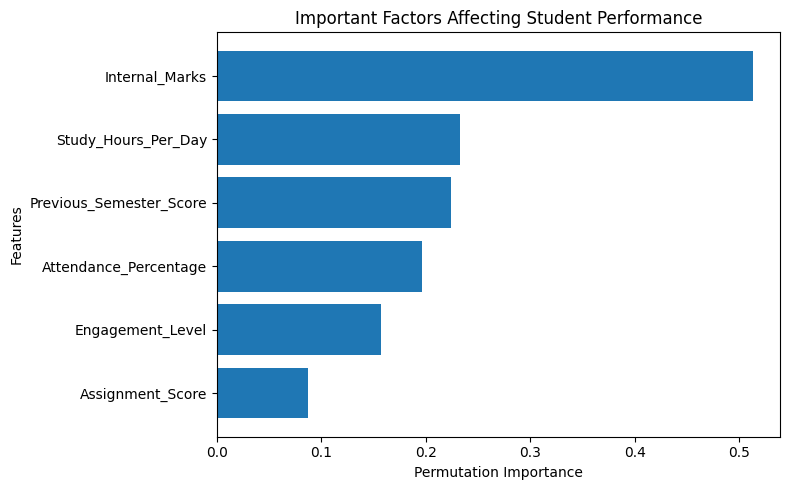

In [301]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Features")
plt.title("Important Factors Affecting Student Performance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

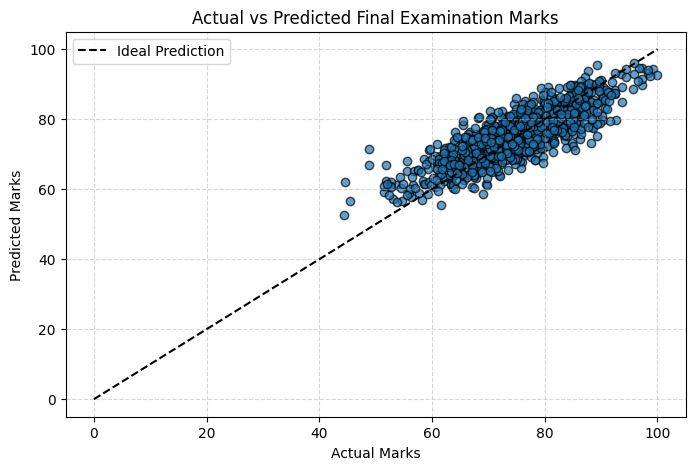

In [302]:
# Compare actual and predicted marks
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    linear_predictions,
    marker="o",
    alpha=0.7,
    edgecolor="black"
)

# Draw the ideal prediction line
plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    color="black",
    label="Ideal Prediction"
)

plt.title("Actual vs Predicted Final Examination Marks")
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")

plt.legend()
plt.grid(linestyle="--", alpha=0.5)
plt.show()

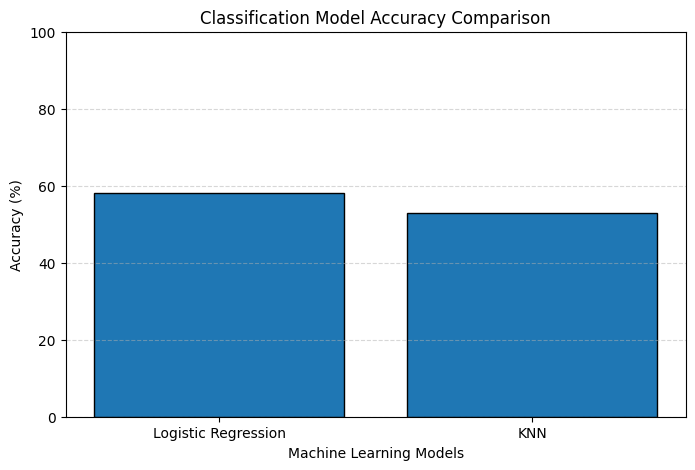

In [303]:
# Prepare model accuracy values
model_names = [
    "Logistic Regression",
    "KNN"
]

model_accuracies = [
    logistic_accuracy,
    knn_accuracy
]

# Plot model accuracy
plt.figure(figsize=(8, 5))

plt.bar(
    model_names,
    model_accuracies,
    edgecolor="black"
)

plt.title("Classification Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

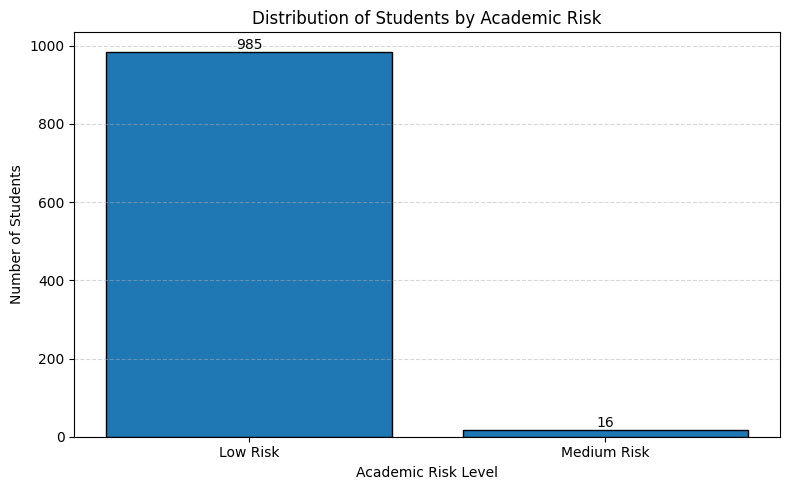

In [304]:
# Count students by academic risk
risk_counts = prediction_results["Academic Risk"].value_counts()

# Plot risk distribution
plt.figure(figsize=(8, 5))

plt.bar(
    risk_counts.index,
    risk_counts.values,
    edgecolor="black"
)

plt.title("Distribution of Students by Academic Risk")
plt.xlabel("Academic Risk Level")
plt.ylabel("Number of Students")

plt.grid(axis="y", linestyle="--", alpha=0.5)

for i, value in enumerate(risk_counts.values):
    plt.text(i, value, str(value), ha="center", va="bottom")

plt.tight_layout()
plt.show()

**Final Output**

In [306]:

# ========== STUDENT PERFORMANCE PREDICTION ==========

print("========== STUDENT PERFORMANCE PREDICTION ==========")

attendance = float(input("Enter Attendance Percentage: "))
internal = float(input("Enter Internal Marks: "))
assignment = float(input("Enter Assignment Score: "))
previous = float(input("Enter Previous Semester Score: "))
study_hours = float(input("Enter Study Hours Per Day: "))
engagement = int(input("Enter Engagement Level (Low=0, Medium=1, High=2): "))

# Create student input
student_data = pd.DataFrame([[
    attendance, internal, assignment,
    previous, study_hours, engagement
]], columns=X.columns)

# 1. Predict final examination marks
predicted_marks = linear_model.predict(student_data)[0]

# 2. Pass/Fail prediction (assuming 40 is passing)
pass_fail = "Pass" if predicted_marks >= 40 else "Fail"

# 3. Academic risk
academic_risk = identify_risk(predicted_marks)

# 4. Student performance segmentation using K-Means
student_cluster_scaled = scaler_kmeans.transform(student_data)
predicted_cluster = kmeans_model.predict(student_cluster_scaled)[0]

cluster_means = df.groupby("Cluster")["Final_Academic_Score"].mean()
sorted_clusters = cluster_means.sort_values()

cluster_labels = {
    sorted_clusters.index[0]: "At-Risk",
    sorted_clusters.index[1]: "Average",
    sorted_clusters.index[2]: "High Performing"
}

performance_group = cluster_labels[predicted_cluster]

# 5. Important factors affecting performance
print("\n========== FINAL PREDICTION RESULT ==========")

print("Predicted Final Examination Marks:", round(predicted_marks, 2))
print("Pass/Fail Prediction:", pass_fail)
print("Academic Risk Level:", academic_risk)
print("Student Performance Segmentation:", performance_group)

print("\nMajor Factors Affecting Student Performance:")
print(feature_importance[["Feature", "Importance"]].to_string(index=False))

print("\n==============================================")


========== STUDENT PERFORMANCE PREDICTION ==========
Enter Attendance Percentage: 50
Enter Internal Marks: 60
Enter Assignment Score: 70
Enter Previous Semester Score: 75
Enter Study Hours Per Day: 4
Enter Engagement Level (Low=0, Medium=1, High=2): 1

========== FINAL PREDICTION RESULT ==========
Predicted Final Examination Marks: 67.58
Pass/Fail Prediction: Pass
Academic Risk Level: Low Risk
Student Performance Segmentation: Average

Major Factors Affecting Student Performance:
                Feature  Importance
         Internal_Marks    0.513351
    Study_Hours_Per_Day    0.232282
Previous_Semester_Score    0.223917
  Attendance_Percentage    0.196231
       Engagement_Level    0.156708
       Assignment_Score    0.087057



In [307]:
# Display final project summary

print("\n==============================================")
print(" STUDENT PERFORMANCE PREDICTION AND")
print(" ACADEMIC RISK ANALYSIS")
print("==============================================")

print("\nDataset Information")
print("Total Students:", len(df))
print("Total Features:", df.shape[1])

print("\nMachine Learning Models")
print("1. Linear Regression")
print("2. Logistic Regression")
print("3. K-Nearest Neighbors")
print("4. K-Means Clustering")

print("\nModel Performance")
print("Linear Regression R2 Score:", round(linear_r2, 3))
print("Linear Regression MAE:", round(linear_mae, 2))
print("Linear Regression RMSE:", round(linear_rmse, 2))
print("Logistic Regression Accuracy:", round(logistic_accuracy, 2), "%")
print("KNN Accuracy:", round(knn_accuracy, 2), "%")
print("K-Means Silhouette Score:", round(max(silhouette_scores), 3))

print("\nStudent Performance Groups")
print(performance_counts)

print("\nAcademic Risk Distribution")
print(risk_counts)

print("\nProject Completed Successfully!")
print("==============================================")


 STUDENT PERFORMANCE PREDICTION AND
 ACADEMIC RISK ANALYSIS

Dataset Information
Total Students: 5003
Total Features: 13

Machine Learning Models
1. Linear Regression
2. Logistic Regression
3. K-Nearest Neighbors
4. K-Means Clustering

Model Performance
Linear Regression R2 Score: 0.672
Linear Regression MAE: 4.07
Linear Regression RMSE: 5.12
Logistic Regression Accuracy: 58.14 %
KNN Accuracy: 52.95 %
K-Means Silhouette Score: 0.119

Student Performance Groups
Performance_Band
Good         2911
Average      1348
Excellent     670
At Risk        74
Name: count, dtype: int64

Academic Risk Distribution
Academic Risk
Low Risk       985
Medium Risk     16
Name: count, dtype: int64

Project Completed Successfully!
